## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [86]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ekamjot Singh

**Date:** 10/19/26

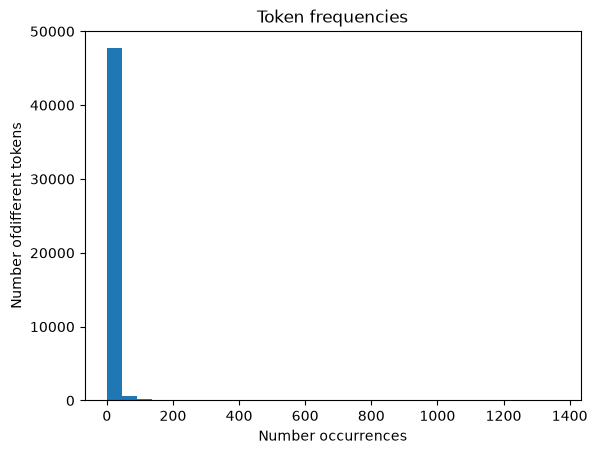

In [87]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

plt.hist(list(token_count.values()), bins=30)
plt.xlabel("Number occurrences")
plt.ylabel("Number ofdifferent tokens")
plt.title("Token frequencies")
plt.show()




I think that most of the tokens happen a couple of times and the histogram is skwerd to the right

In [88]:
df = pd.read_parquet("data/Phishing_clean.parquet")
X = df.drop(columns="Email Type")
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression().fit(X_train, y_train)
print("The Training R-squared:", model.score(X_train, y_train))
print("The Test R-squared:", model.score(X_test, y_test))


The Training R-squared: 0.7670143724934355
The Test R-squared: 0.665871843884792


In [89]:
coefficients = pd.Series(model.coef_, index=X.columns)
largest_words = coefficients.abs().sort_values(ascending=False).head(10).index
print(coefficients[largest_words])


intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
a:active             0.574480
gray;               -0.574480
dtype: float64


THe above output shows the top words with biggest coefficent value and a postiive coefficient raises the predicted value of phishing and negative lowers it

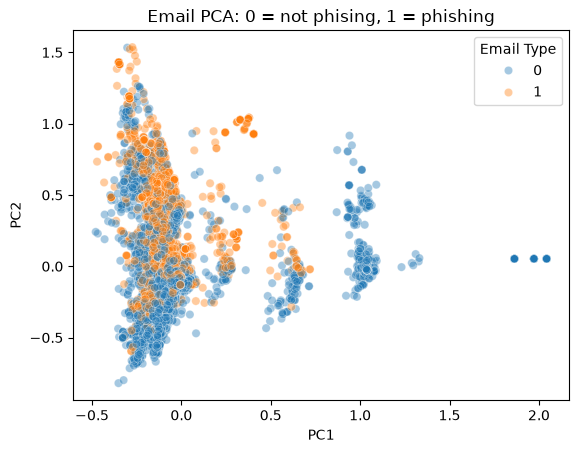

In [90]:
pca = PCA(n_components=2).fit(X)
X_pca = pca.transform(X)

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, alpha=0.4)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Email PCA: 0 = not phising, 1 = phishing")
plt.show()


Like the 2 types have a lot of overlap and the group on the left but the smaller groups on the right are most like non phishinh

In [91]:
pca = PCA(n_components=2610).fit(X_train)
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)

pca_model = LinearRegression().fit(X_train_pca, y_train)
print("The PCA training R-squared:", pca_model.score(X_train_pca, y_train))
print("ThePCA test R-squared:", pca_model.score(X_test_pca, y_test))


The PCA training R-squared: 0.7662326827745849
ThePCA test R-squared: 0.6683390643101162


The regrsionn we had oirignally has trainign R-squared for about 0.767 and test of around 0.6659 PCA, I think that PCA  gives a sligthly  lower traing score, with pca the R squared is 0.7662 and 0.668

I think that PCA like makes cominig the overlapping word feature sinto components that are uncorrelated in teh trainig data and keep the fewer ones reduces number predictors. Can make regression more stable but doesnt mean you will get better prediciton.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** d7cd63016d0bd952487d01a763dc3aa8986abdb8
- **AI tool and model used:** gpt 5.6 sol

### *Prompts used

1. I think my question 4 is kinda wrong can you suggest a imrprovement
2. for the pca part suggest another statstic that oculd help explain what the compenets show

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Label the training and test R-squared values for both models in Q4. State that PCA has a slightly lower training score and a slightly higher test score, with very similar overall performance.
2. Optionally report `pca.explained_variance_ratio_.sum()` after fitting the 2,610-component PCA to show the proportion of feature variance retained. Q4 does not require this statistic.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept  | I think that this makes the comparision clearer and that the original values of 0.767 and 0.665 and the PCA values are 0.762 and 0.668 and that I think that these show a small test increase and a smlal trainig decrease.  |
| 2 | reject | The statstic is very useful I may use it for futurue reference but the question asks for regresion R squaredand comparision  |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

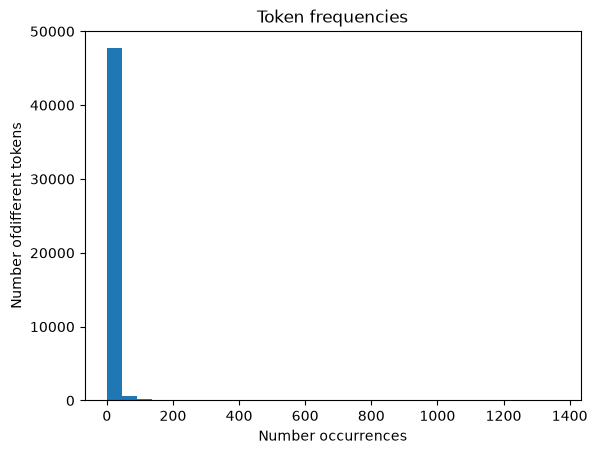

In [92]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

plt.hist(list(token_count.values()), bins=30)
plt.xlabel("Number occurrences")
plt.ylabel("Number ofdifferent tokens")
plt.title("Token frequencies")
plt.show()




I think that most of the tokens happen a couple of times and the histogram is skwerd to the right

In [93]:
coefficients = pd.Series(model.coef_, index=X.columns)
largest_words = coefficients.abs().sort_values(ascending=False).head(10).index
print(coefficients[largest_words])


intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
a:active             0.574480
gray;               -0.574480
dtype: float64


In [94]:
df = pd.read_parquet("data/Phishing_clean.parquet")
X = df.drop(columns="Email Type")
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression().fit(X_train, y_train)
print("The Training R-squared:", model.score(X_train, y_train))
print("The Test R-squared:", model.score(X_test, y_test))


The Training R-squared: 0.7670143724934355
The Test R-squared: 0.665871843884792


In [95]:
coefficients = pd.Series(model.coef_, index=X.columns)
largest_words = coefficients.abs().sort_values(ascending=False).head(10).index
print(coefficients[largest_words])


intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
a:active             0.574480
gray;               -0.574480
dtype: float64


Like the 2 types have a lot of overlap and the group on the left but the smaller groups on the right are most like non phishinh

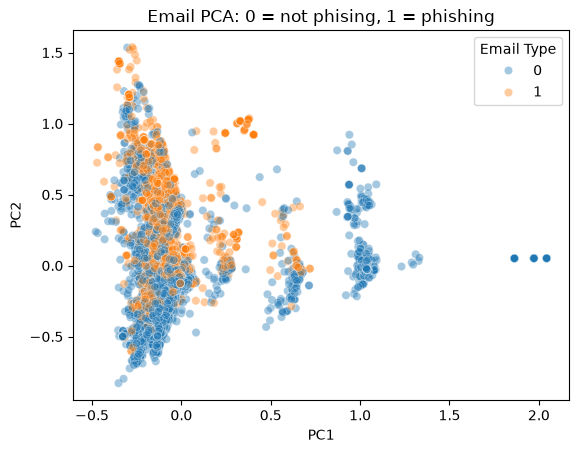

In [96]:
pca = PCA(n_components=2).fit(X)
X_pca = pca.transform(X)

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, alpha=0.4)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Email PCA: 0 = not phising, 1 = phishing")
plt.show()


In [97]:
pca = PCA(n_components=2610).fit(X_train)
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)

pca_model = LinearRegression().fit(X_train_pca, y_train)
print("The PCA training R-squared:", pca_model.score(X_train_pca, y_train))
print("ThePCA test R-squared:", pca_model.score(X_test_pca, y_test))


The PCA training R-squared: 0.7662326827745849
ThePCA test R-squared: 0.6683390643101162


The original regression has training R-squared of about 0.7670 and test R-squared of about 0.6659. The PCA regression has training R-squared of about 0.7662 and test R-squared of about 0.6683. PCA has a slightly lower training score and a slightly higher test score. Overall, the two models perform very similarly.

I think that PCA like makes cominig the overlapping word feature sinto components that are uncorrelated in teh trainig data and keep the fewer ones reduces number predictors. Can make regression more stable but doesnt mean you will get better prediciton.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

I think the main imrpovment that Ai did was mkaing the question 4comparison clearer. It helped me explain properly that the revised score is for training and which for tetsing and it also explains that PCA has lower trainig score and higher test score. The second suggestion was to report the amoutn of variance in PCA. I rejected this because it asks for regression but I was curious about more stastical models to reprsent this.  I think that the limitations on this one, since there was less problems to do there was less room for error, so the ai model tried to pick up small thigns or whatever it could find in order to help me revise. Overall it does fell a bit marginally imrpoved things and there was no content that I had to change so it did its job the best it could  with the things it was given.